# Exploring the Titanic Dataset

This notebook explores the Kaggle Titanic training data and asks: **What passenger characteristics were associated with higher survival in this sample?** The comparisons are descriptive and do not show that any characteristic caused an outcome.

Download `train.csv` from the [Kaggle competition data page](https://www.kaggle.com/competitions/titanic/data) and save it at `data/train.csv` before running the notebook.

## 1. Load and inspect the dataset

In [1]:
from IPython.display import display, Image
import pandas as pd
from titanic_eda import load_data, inspect_data, group_survival_rates, observations, create_charts

df = load_data()
stats = inspect_data(df)
print(f"Shape: {stats['shape'][0]} rows × {stats['shape'][1] - 2} source columns")
print(f"Exact duplicate rows: {stats['duplicates']}")
display(df.head())

Shape: 891 rows × 12 source columns
Exact duplicate rows: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survival status,Age group
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Did not survive,Adult (18–35)
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Survived,Middle age (36–59)
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Survived,Adult (18–35)
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Survived,Adult (18–35)
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Did not survive,Adult (18–35)


The two additional columns are derived for analysis: `Survival status` is a readable outcome label and `Age group` bins recorded ages. The source columns remain available as loaded.

In [2]:
dtype_table = df.dtypes.astype(str).rename('dtype').to_frame()
missing_table = df.isna().sum().rename('missing values').to_frame()
display(dtype_table)
display(missing_table.sort_values('missing values', ascending=False))

,dtype
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64


,missing values
Cabin,687
Age,177
Age group,177
Embarked,2
Survived,0
PassengerId,0
Sex,0
Name,0
Pclass,0
SibSp,0


`Cabin` and `Age` contain many missing values, while `Embarked` has only a small number. Age-based charts below omit passengers whose age is unknown; the other group comparisons use all rows with an outcome. This is an EDA exercise, so missing ages are not silently imputed.

## 2. Overall survival

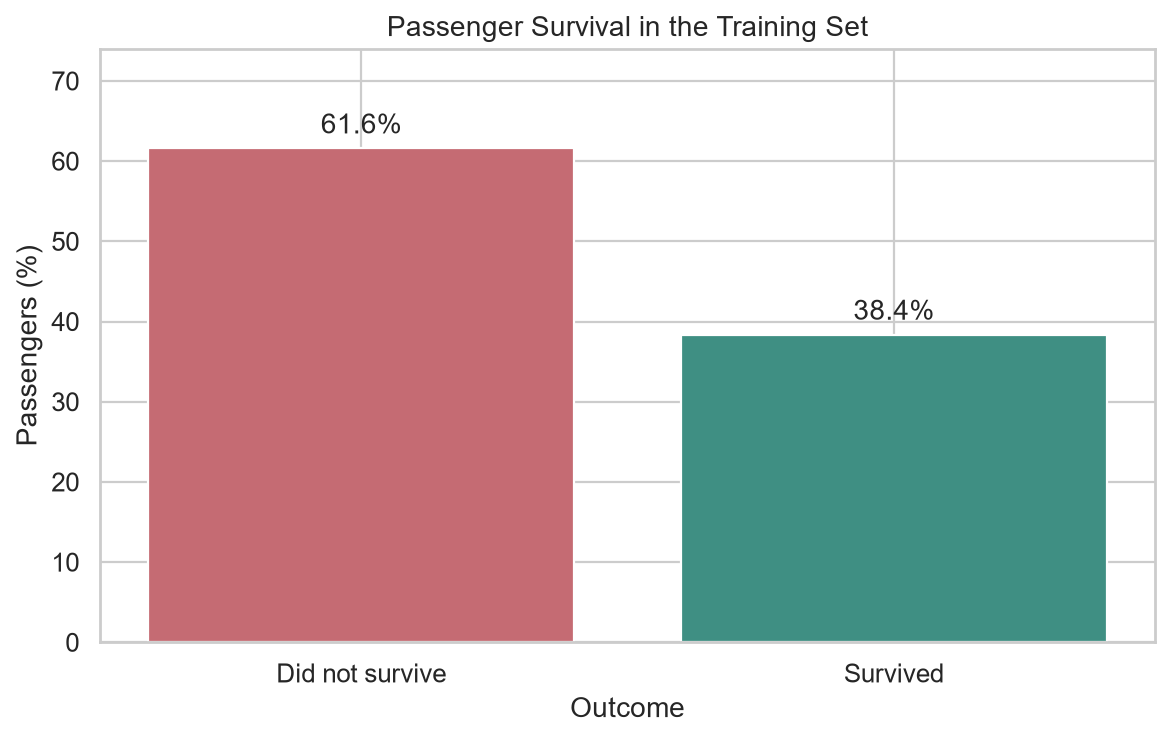

38.4% of passengers in the training sample survived.


In [3]:
chart_files = create_charts(df)
display(Image(filename=str(chart_files[0])))
print(f"{df['Survived'].mean():.1%} of passengers in the training sample survived.")

**Observation:** The chart shows each outcome as a percentage of all passengers, making the overall imbalance between survivors and non-survivors clear.

## 3. Survival by sex

,Sex,survival_rate,passengers,known_outcomes
0,female,74.2%,314,314
1,male,18.9%,577,577


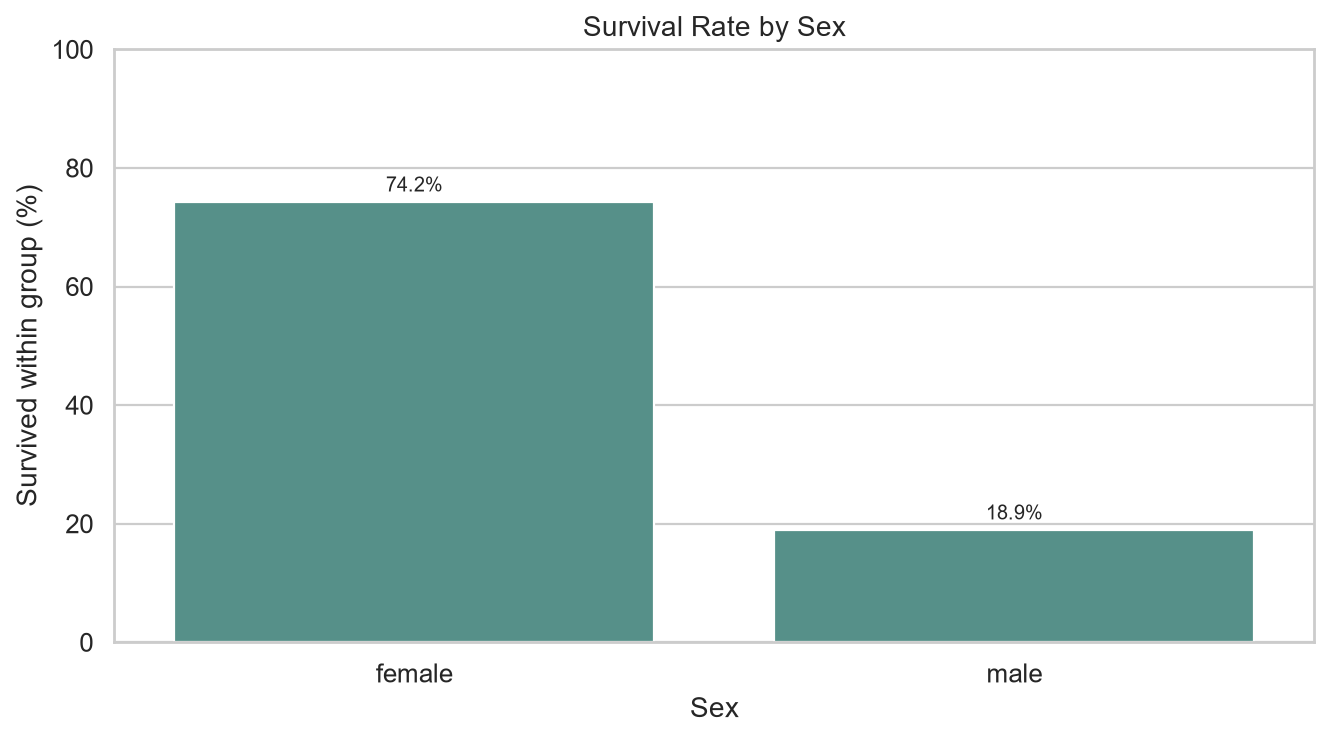

In this sample, 74.2% of women survived versus 18.9% of men (a 55.3-percentage-point difference).


In [4]:
display(group_survival_rates(df, 'Sex').style.format({'survival_rate': '{:.1f}%', 'passengers': '{:,.0f}'}))
display(Image(filename=str(chart_files[1])))
print(observations(df)['sex'])

**Observation:** Each bar is the percentage who survived within that sex group, not a raw passenger count. In this sample, the observed survival rate is substantially higher for women.

## 4. Survival by passenger class

,Pclass,survival_rate,passengers,known_outcomes
0,1,63.0%,216,216
1,2,47.3%,184,184
2,3,24.2%,491,491


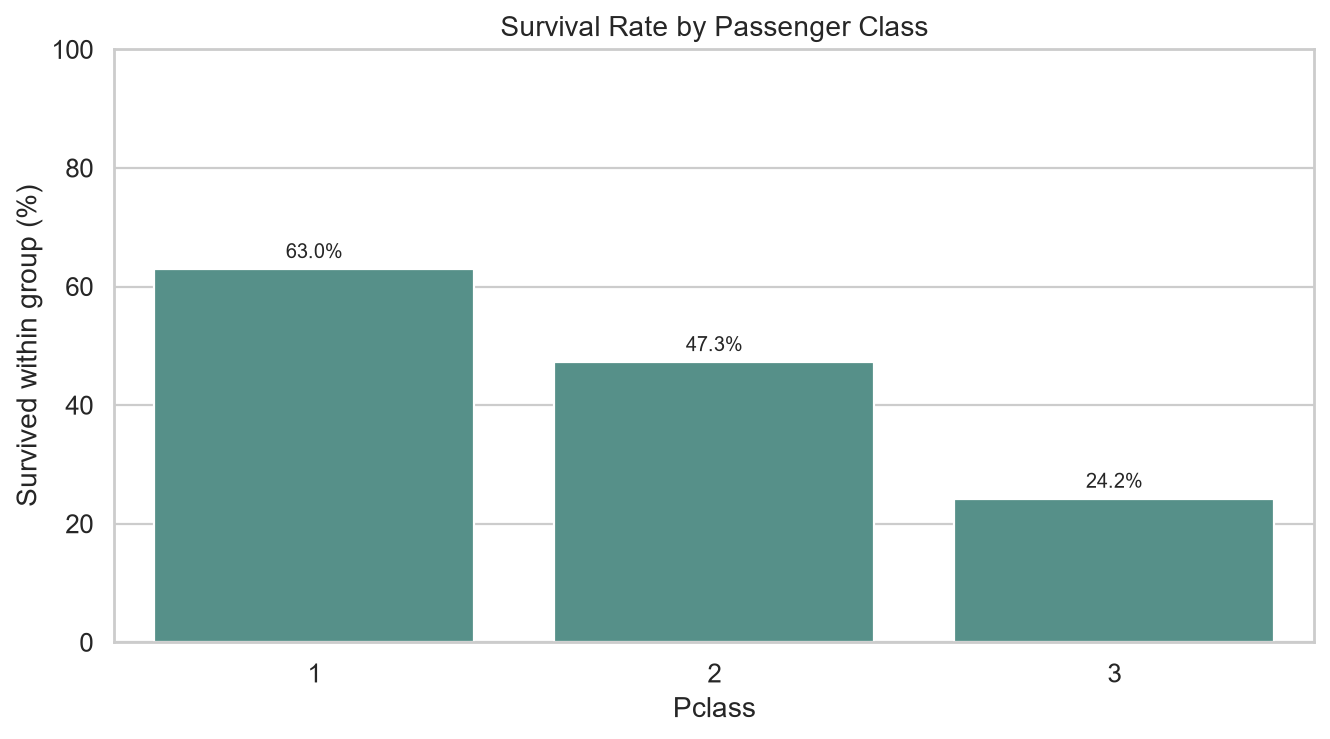

Survival was 63.0% in 1st class and 24.2% in 3rd class (38.7 percentage points apart).


In [5]:
display(group_survival_rates(df, 'Pclass').style.format({'survival_rate': '{:.1f}%', 'passengers': '{:,.0f}'}))
display(Image(filename=str(chart_files[2])))
print(observations(df)['class'])

**Observation:** The chart compares survival proportions within each class. In the training sample, 1st class has a higher survival rate than 3rd class; this association alone does not establish why.

## 5. Survival by age group

,Age group,survival_rate,passengers,known_outcomes
0,Child (0–12),58.0%,69,69
1,Teen (13–17),47.7%,44,44
2,Adult (18–35),38.0%,384,384
3,Middle age (36–59),39.8%,191,191
4,Senior (60+),26.9%,26,26


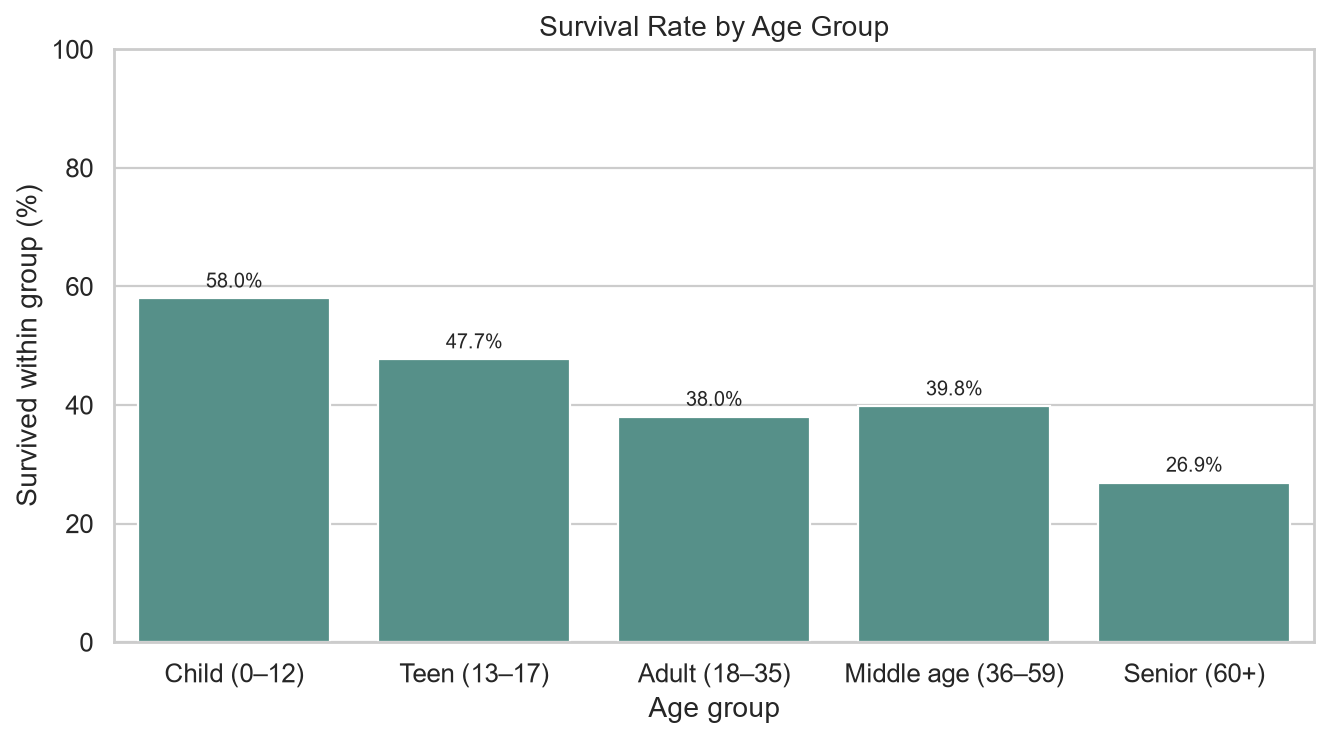

Among passengers with a recorded age, the highest survival rate was in Child (0–12) (58.0%). Ages are missing for 177 passengers, so this comparison excludes them.


In [6]:
age_rates = group_survival_rates(df, 'Age group')
display(age_rates.style.format({'survival_rate': '{:.1f}%', 'passengers': '{:,.0f}'}))
display(Image(filename=str(chart_files[3])))
print(observations(df)['age'])

**Observation:** The age bands make the survival proportions easier to compare. The youngest age group has the highest rate in this sample. The group rates are based only on passengers with a recorded age, and some bands contain fewer people than others.

## 6. Age distribution among survivors and non-survivors

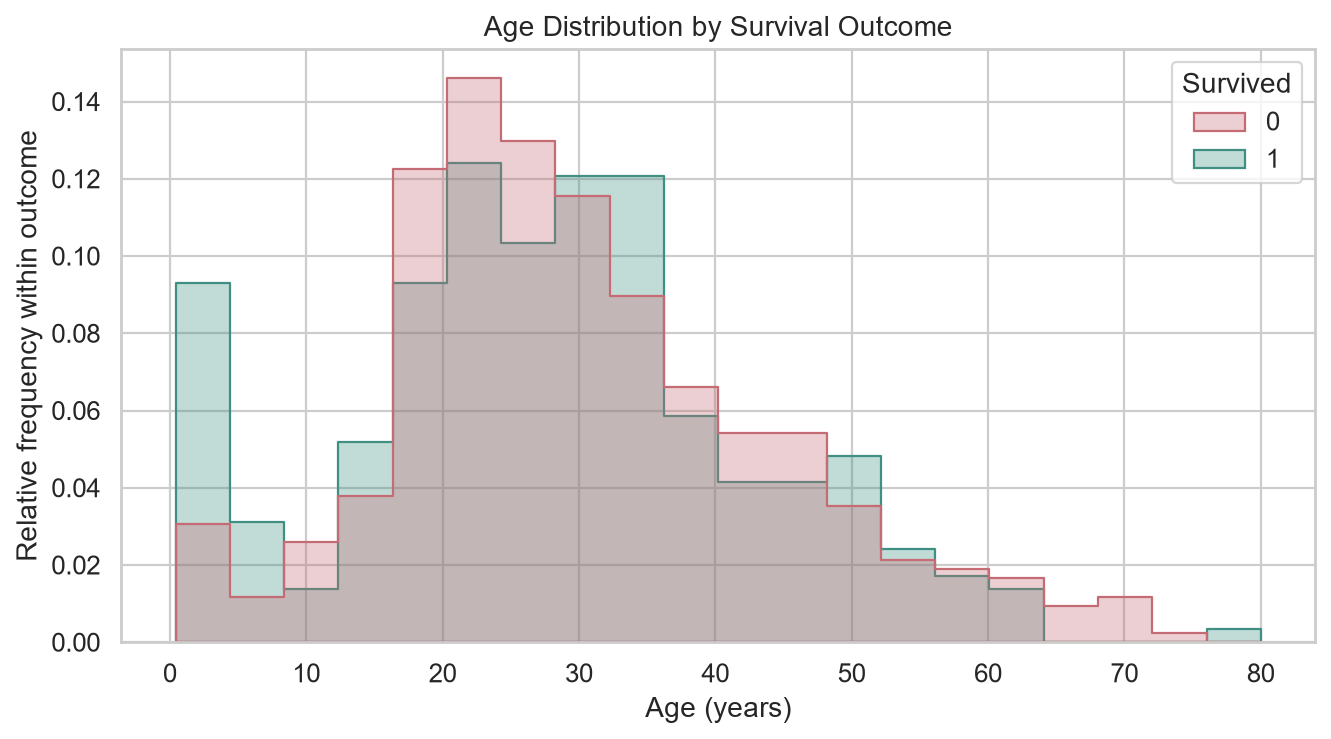

Each histogram group is normalized separately (relative frequency); bar heights compare age distributions rather than raw group sizes.


In [7]:
display(Image(filename=str(chart_files[4])))
print(observations(df)['age_distribution'])

**Observation:** Each outcome's age histogram is normalized separately, so the shapes can be compared despite the different numbers of survivors and non-survivors. The chart describes only recorded ages; 177 ages are missing in the original training data.

## Summary

In this training sample, survival rates differ by sex, passenger class, and age group. These are descriptive associations in historical data, not causal effects or individual predictions.